# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [2]:
# Import necessary libraries 🔧
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# Load your uploaded file (path "/content/listings.csv.gz") 🔧
df = pd.read_csv("/content/listings.csv.gz")

In [ ]:
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,103760,https://www.airbnb.com/rooms/103760,20260627225958,2026-06-28,city scrape,Central Centre 5 min walk to/from Central MTR,"Located right in the heart of Central, this 2 ...",NaN,https://a0.muscache.com/pictures/815221/056993...,304876,...,4.63,4.72,4.41,NaN,NaN,2,2,0,0,1.72
1,163664,https://www.airbnb.com/rooms/163664,20260627225958,2026-06-28,city scrape,Soho off Hollywood Road P4,"Fun Fact: Possession St, is where the British ...",NaN,https://a0.muscache.com/pictures/15184030/8d06...,304876,...,4.58,4.68,4.31,NaN,NaN,2,2,0,0,1.24
2,248140,https://www.airbnb.com/rooms/248140,20260627225958,2026-07-03,previous scrape,Bright Studio - Soho - Central HK,Our bright studio apartment is perfect for vis...,NaN,https://a0.muscache.com/pictures/4e5463bc-38be...,1300549,...,4.97,4.76,4.79,NaN,NaN,1,1,0,0,1.34
3,263081,https://www.airbnb.com/rooms/263081,20260627225958,2026-06-29,city scrape,"3 睡房, 2500 平方呎 有工人 Family Friendly! 在中環半山 有車","Mid Level on the top of central, Next to the m...",NaN,https://a0.muscache.com/pictures/7348025/73278...,1370155,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
4,306515,https://www.airbnb.com/rooms/306515,20260627225958,2026-06-28,city scrape,"HongKong,Central Bright Double Room",NaN,NaN,https://a0.muscache.com/pictures/3335548/00a8d...,1576511,...,4.84,4.89,4.79,NaN,NaN,1,1,0,0,0.11


In [5]:
df.describe()

,id,scrape_id,neighborhood_overview,host_id,host_profile_id,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,6.734000e+03,6.734000e+03,0.0,6.734000e+03,6.734000e+03,0.0,6734.000000,6734.000000,6734.000000,6734.000000,...,3755.000000,3755.000000,3755.000000,0.0,0.0,6734.000000,6734.000000,6734.000000,6734.000000,3756.000000
mean,7.263867e+17,2.026063e+13,NaN,1.001945e+16,1.472549e+18,NaN,7.984556,5.604099,6.957677,5.319127,...,4.692272,4.736077,4.481142,NaN,NaN,88.888625,13.703000,74.823582,0.310811,0.794507
std,6.345036e+17,2.039214e+00,NaN,1.296296e+17,3.200744e+16,NaN,4.080986,3.520632,4.239961,3.392253,...,0.570111,0.475659,0.668502,NaN,NaN,119.732514,26.103514,115.369265,1.227832,1.073337
min,1.037600e+05,2.026063e+13,NaN,6.303800e+04,1.462508e+18,NaN,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.010000
25%,3.356930e+07,2.026063e+13,NaN,2.331877e+07,1.462946e+18,NaN,3.000000,2.000000,3.000000,2.000000,...,4.660000,4.700000,4.330000,NaN,NaN,3.000000,1.000000,0.000000,0.000000,0.120000
50%,8.426241e+17,2.026063e+13,NaN,9.724013e+07,1.466837e+18,NaN,9.000000,5.000000,8.000000,5.000000,...,4.890000,4.890000,4.670000,NaN,NaN,22.000000,4.000000,10.000000,0.000000,0.350000
75%,1.284325e+18,2.026063e+13,NaN,4.758896e+08,1.470145e+18,NaN,11.000000,9.000000,10.000000,8.000000,...,5.000000,5.000000,4.880000,NaN,NaN,126.000000,19.000000,99.000000,0.000000,1.000000
max,1.716294e+18,2.026063e+13,NaN,1.716070e+18,1.716070e+18,NaN,16.000000,11.000000,15.000000,11.000000,...,5.000000,5.000000,5.000000,NaN,NaN,345.000000,135.000000,332.000000,12.000000,9.090000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6734 entries, 0 to 6733
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            6734 non-null   int64  
 1   listing_url                                   6734 non-null   object 
 2   scrape_id                                     6734 non-null   int64  
 3   last_scraped                                  6734 non-null   object 
 4   source                                        6734 non-null   object 
 5   name                                          6734 non-null   object 
 6   description                                   6627 non-null   object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   6733 non-null   object 
 9   host_id                                       6734 non-null   i

## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

In [7]:
df.shape

(6734, 90)

In [8]:
#Count the null values of each column
null_counts = df.isnull().sum()
null_columns = null_counts[null_counts > 0]
display(null_columns)

,0
description,107
neighborhood_overview,6734
picture_url,1
host_since,6734
host_location,2243
host_about,2524
host_response_time,6734
host_response_rate,6734
host_acceptance_rate,6734
host_thumbnail_url,6734


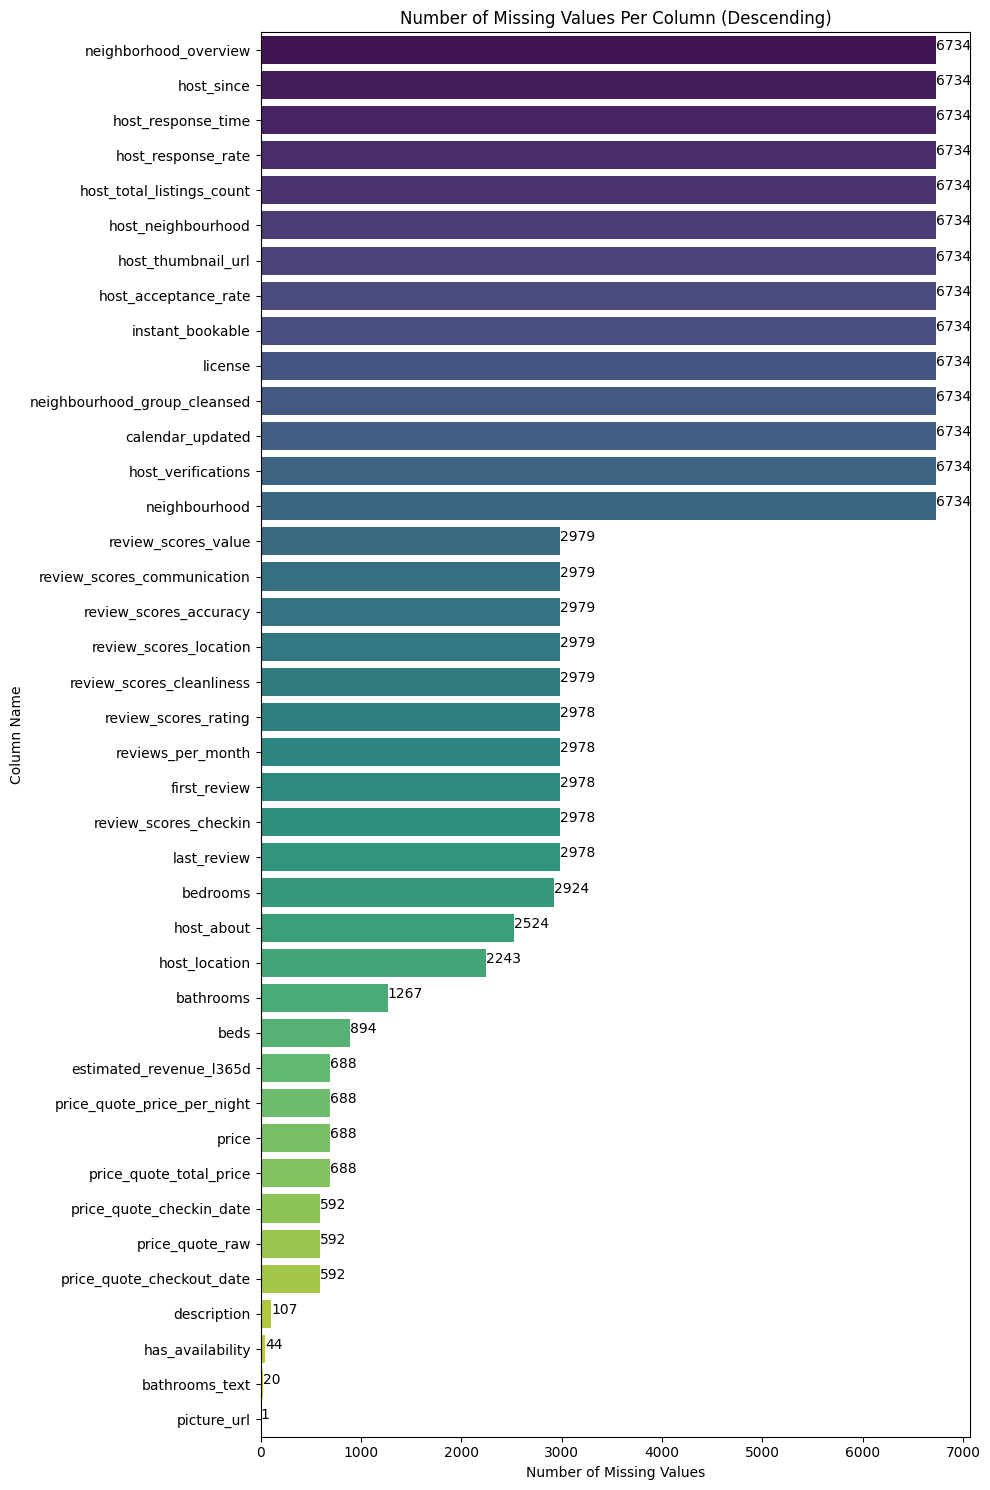

In [9]:
#Create visuals to show what columns are missing values
plt.figure(figsize=(10, 15))
sorted_null_columns = null_columns.sort_values(ascending=False)
sns.barplot(x=sorted_null_columns.values, y=sorted_null_columns.index, palette='viridis', hue=sorted_null_columns.index, legend=False)
plt.title('Number of Missing Values Per Column (Descending)')
plt.xlabel('Number of Missing Values')
plt.ylabel('Column Name')

# Add number counts to each bar
for index, value in enumerate(sorted_null_columns.values):
    plt.text(value, index, str(value))

plt.tight_layout()
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. 40 columns are all missing some data. 14 columns are missing all values.

2. neighborhood, review_score* columns, bathrooms, beds, price, bedrooms

3. host_since, license, calendar_updated, host_thumbnail_url, first_review


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [14]:
# Add code here 🔧
drop_columns = ['host_since', 'calendar_updated', 'host_thumbnail_url', 'neighbourhood_group_cleansed']
df = df.drop(columns=drop_columns, errors='ignore')

Reasons for each drop

---


1. 'host_since' was dropped because it was completely empty and will not add or subract anything at this point. We could invstigate however why that information has not been collected.
2. 'calendar_updated' was droppped because it was completely empty and therefore would not affect the analysis.
3. 'host_thumbnail_url' was dropped again because of the missingness. It will not affect the analysis in any way.
4. 'neighborhhhod_group_cleansed' was dropped. I am honestly not sure what this column is for. It is empty completely and will not contribute to the analysis.

In [15]:
#Checking to see if I dropped the 4 columns
df.shape

(6734, 86)

### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I dropped: host_since, calendar_updated, host_thumbnail_url and neighborhood_group_cleansed.
I wanted to drop more columns but limited to 4 as per  asiignment instructions.

2. The columns are completely empty and their values cannot be calculated.

3. In this case, since they are completely empty, nothing.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6734 entries, 0 to 6733
Data columns (total 86 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            6734 non-null   int64  
 1   listing_url                                   6734 non-null   object 
 2   scrape_id                                     6734 non-null   int64  
 3   last_scraped                                  6734 non-null   object 
 4   source                                        6734 non-null   object 
 5   name                                          6734 non-null   object 
 6   description                                   6627 non-null   object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   6733 non-null   object 
 9   host_id                                       6734 non-null   i

In [21]:
# Clean the price column by removing '$' and ',' then convert to float
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
df['price'].head()

,price
0,1181.02
1,822.05
2,NaN
3,24910.60
4,1077.87


In [28]:
# Use quoted nightly price first, if available
df['price'] = df['price'].fillna(df['price_quote_price_per_night'])

# Estimate remaining missing prices using similar listings
df['price'] = df['price'].fillna(
    df.groupby(['neighbourhood_cleansed', 'room_type', 'property_type'])['price']
      .transform('median')
)

# Last-resort fallback for any groups with too little data
df['price'] = df['price'].fillna(df['price'].median())

In [29]:
df['review_status'] = df['review_scores_rating'].isna().map({
    True: 'No reviews yet',
    False: 'Has reviews'
})

### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. The price column and the review_scores_rating

2. I used the median for the price because this will reduce and intorduction of skewedness. I treated missingness as a feature for the reviews because those are hard to estimate.

3. The risk for price is masking the variability on the pricing. The medians will pull the data tighter together which potentially would have been spread apart. The risk of using missingness as a feature is that it will be hard to include the observations with empty cells.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

In [34]:
# Convert from text/object to a date format
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce')
print(df['last_review'].dtype)

datetime64[ns]


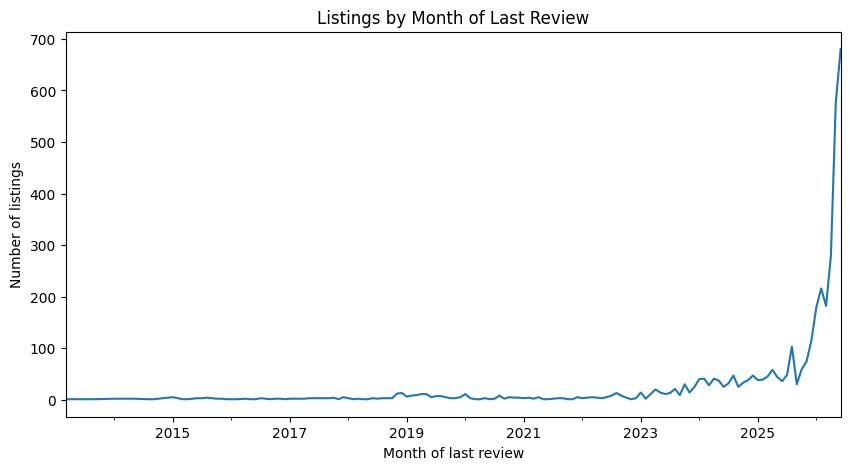

In [35]:
df['last_review'].dropna().dt.to_period('M').value_counts().sort_index().plot(
    kind='line',
    figsize=(10, 5)
)

plt.xlabel('Month of last review')
plt.ylabel('Number of listings')
plt.title('Listings by Month of Last Review')
plt.show()

### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. The last_review column

2. I changed the data type from object to datetime64 because it's supposed to be time based.

3. It helps because you can now make engineer time series features later.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [37]:
# Count duplicate entries in the 'id' column
duplicate_id_count = df.duplicated(subset=['id']).sum()
print(f"Number of duplicate listing IDs: {duplicate_id_count}")

# If duplicates exist, show them
if duplicate_id_count > 0:
    display(df[df.duplicated(subset=['id'], keep=False)].sort_values(by='id').head())
else:
    print("All listing IDs are unique.")

Number of duplicate listing IDs: 0
All listing IDs are unique.


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. There were no duplicate rows in my dataset.

2. I did not have to drop or keep any.

3. They can inflate aggregates and skew statistical anaylises.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [49]:
cols_to_drop = [
    # Completely empty columns
    'neighborhood_overview',
    'host_response_time',
    'host_response_rate',
    'host_acceptance_rate',
    'host_neighbourhood',
    'host_total_listings_count',
    'host_verifications',
    'neighbourhood',
    'license',
    'instant_bookable',

    # Scraping/technical metadata
    'scrape_id',
    'last_scraped',
    'calendar_last_scraped',

    # Raw unstructured quote information
    'price_quote_raw'
]

df = df.drop(columns=cols_to_drop)

In [50]:
df.shape

(6734, 73)

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6734 entries, 0 to 6733
Data columns (total 73 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            6734 non-null   int64         
 1   listing_url                                   6734 non-null   object        
 2   source                                        6734 non-null   object        
 3   name                                          6734 non-null   object        
 4   description                                   6627 non-null   object        
 5   picture_url                                   6733 non-null   object        
 6   host_id                                       6734 non-null   int64         
 7   host_url                                      6734 non-null   object        
 8   host_profile_id                               6734 non-null   int64 

In [52]:
# 1. Convert remaining date columns
date_cols = [
    'first_review',
    'price_quote_checkin_date',
    'price_quote_checkout_date'
]

df[date_cols] = df[date_cols].apply(pd.to_datetime, errors='coerce')


# 2. Convert true/false fields from object to Boolean
bool_cols = [
    'host_is_superhost',
    'host_has_profile_pic',
    'host_identity_verified',
    'has_availability'
]

for col in bool_cols:
    df[col] = (
        df[col]
        .astype('string')
        .str.lower()
        .map({'t': True, 'f': False, 'true': True, 'false': False})
        .astype('boolean')
    )


# 3. Optional: Convert repeated labels to category
category_cols = [
    'source',
    'neighbourhood_cleansed',
    'property_type',
    'room_type',
    'review_status'
]

df[category_cols] = df[category_cols].astype('category')


# Check the revised data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6734 entries, 0 to 6733
Data columns (total 73 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            6734 non-null   int64         
 1   listing_url                                   6734 non-null   object        
 2   source                                        6734 non-null   category      
 3   name                                          6734 non-null   object        
 4   description                                   6627 non-null   object        
 5   picture_url                                   6733 non-null   object        
 6   host_id                                       6734 non-null   int64         
 7   host_url                                      6734 non-null   object        
 8   host_profile_id                               6734 non-null   int64 

In [53]:
# export csv here 🔧
df.to_csv('cleaned_airbnb_data_6.csv', index=False)

## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. __  Finding, removing and visualizing missing values made it a little difficult for me. It was the coding. I was aware of the class concepts but not the coding skills.
2. __  In the end, I ended up having to drop all if the completely empty columns because I have no way of investigating what happened to them. A few of them were not useful but some of them would have been nice data to have.
3. __  Cleaned data would benefit from having less noise from the cleaned data. All those unncessary columns were overwhelming to look at yet added nothing. They will save time by keeping cleaned data.
4. __  If I had more time, I would impute more values and see what I can do for some values that will contribute in either direction such as bedrooms. There is a lot of empty rows n that column.
5. __  I think this is foundational learning of data analysis and it relates to my goal in buidling the skill to do so.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "Shingi_assignment_06_data_cleaning.ipynb"